# DS391 — Big Data Analytics | Project 1
## From Social-Media Records to a Marketing Decision
**Student:** _Write your name_  
**Instructor:** Dr. Raja Noshad Jamil  
**Tools:** Google Colab, Python, Pandas, NumPy, Matplotlib

**Business question:** How do social-media engagement patterns vary by platform and sentiment, and what could a marketer test next?

> **How to use:** Open in Google Colab, select **Runtime → Run all**. The first code cell attempts to download the teacher-recommended CSV; if that fails, it prompts you to upload `social_media_sentiment_raw.csv`. Read the results and edit the marked student reflection sections before submitting. **Do not present repeated rows as new observations.**

## 1. Dataset source, provenance, and license check
**Teacher-recommended repository:** https://github.com/mrudukp/social-media-sentiment-analysis  
**CSV:** https://github.com/mrudukp/social-media-sentiment-analysis/blob/main/social_media_sentiment_raw.csv  
**Repository author:** Mrudula KP  
**Repository description:** 2,260 raw records and 13 columns, covering multiple platforms and countries.

**Provenance limitation:** The repository's description does not establish that the data represents Pakistani clothing brands, nor does it independently verify how every record was collected. The repository is a starting point, not a verified sample of Pakistan's market. **License:** Inspect the current repository and dataset terms before redistribution; do not assume a particular license because the repository is publicly accessible.

**Observational unit:** One row is intended to represent one social-media post, not one customer or advertising campaign. This dataset does not establish paid advertising ROI or ROAS.

In [13]:
import pandas as pd
import numpy as np
from google.colab import files
from io import BytesIO

# Upload CSV file from your computer
uploaded = files.upload()

# Get the uploaded file name
filename = list(uploaded.keys())[0]

# Read the CSV file
df = pd.read_csv(BytesIO(uploaded[filename]))

# Display dataset information
print("File uploaded successfully!")
print("File name:", filename)
print("Total rows and columns:", df.shape)

# Show first 5 rows
display(df.head())


Saving social_media_sentiment_raw.csv to social_media_sentiment_raw (2).csv
File uploaded successfully!
File name: social_media_sentiment_raw (2).csv
Total rows and columns: (2260, 13)


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive


## 2. Data dictionary
Confirm these definitions against the actual CSV. These are the fields described by the repository; missing columns are flagged by the notebook.

In [14]:
raw_df = df

dictionary = {
    'post_id': 'Identifier for a post',
    'timestamp': 'Date/time associated with the post',
    'platform': 'Social network name',
    'user': 'User/account label',
    'followers_count': 'Reported follower count',
    'verified': 'Account verification indicator',
    'text': 'Post text or caption',
    'hashtags': 'Hashtag text',
    'country': 'Country label',
    'likes': 'Reported like count',
    'retweets_shares': 'Reported repost/share count',
    'comments': 'Reported comment count',
    'sentiment': 'Provided sentiment category'
}

data_dictionary = pd.DataFrame([
    {
        'Column': c,
        'Meaning': dictionary.get(c, 'Review manually'),
        'Data Type': str(raw_df[c].dtype),
        'Missing Values': int(raw_df[c].isna().sum())
    }
    for c in raw_df.columns
])

display(data_dictionary)

print("Expected columns absent:")
print(sorted(set(dictionary) - set(raw_df.columns)))

,Column,Meaning,Data Type,Missing Values
0,post_id,Identifier for a post,object,0
1,timestamp,Date/time associated with the post,object,0
2,platform,Social network name,object,0
3,user,User/account label,object,0
4,followers_count,Reported follower count,object,90
5,verified,Account verification indicator,object,44
6,text,Post text or caption,object,0
7,hashtags,Hashtag text,object,788
8,country,Country label,object,126
9,likes,Reported like count,int64,0


Expected columns absent:
[]


## 3. Raw data-quality audit
**Important:** Missing does not automatically mean zero. Record problems before applying transparent cleaning rules.

In [15]:
print('Rows:',len(raw_df),'Columns:',raw_df.shape[1])
print('Duplicate full rows:',int(raw_df.duplicated().sum()))
if 'post_id' in raw_df:
    print('Repeated non-null post IDs:',int(raw_df['post_id'].dropna().duplicated().sum()))
print('Missing values per column:')
display(raw_df.isna().sum().to_frame('missing_count'))
print('Data types:')
display(raw_df.dtypes.to_frame('dtype'))
print('Raw numerical summary:')
display(raw_df.describe(include='all').T)

Rows: 2260 Columns: 13
Duplicate full rows: 44
Repeated non-null post IDs: 60
Missing values per column:


,missing_count
post_id,0
timestamp,0
platform,0
user,0
followers_count,90
verified,44
text,0
hashtags,788
country,126
likes,0


Data types:


,dtype
post_id,object
timestamp,object
platform,object
user,object
followers_count,object
verified,object
text,object
hashtags,object
country,object
likes,int64


Raw numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
post_id,2260,2200,P100054,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,2260,2200,2023-08-13 06:24:13,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,2260,10,Twitter,691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user,2260,2185,liam_2262,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
followers_count,2170,1814,410.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verified,2216,2,No,2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,2260,150,"Best app experience ever, highly recommend to ...",27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hashtags,1472,662,#Health,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,2134,24,USA,433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,2260.0,NaN,NaN,NaN,35.94646,16.56231,-1.0,25.0,33.0,44.0,126.0


## 4. Clean a working copy
Rules: remove exact duplicate rows; trim/standardize key categories; parse timestamp; convert numeric engagement fields; turn impossible negative counts into missing values (not zero); retain missing values rather than silently replacing them. Duplicate post IDs are **reported**, not automatically removed, because their meaning requires checking.

In [16]:
df = raw_df.drop_duplicates().copy()
for col in ['platform','sentiment','country']:
    if col in df:
        df[col] = df[col].astype('string').str.strip().str.title()
        df[col] = df[col].replace('',pd.NA)
if 'timestamp' in df:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce', utc=True)
for col in ['likes','comments','retweets_shares','followers_count']:
    if col in df:
        cleaned = df[col].astype('string').str.replace(',','',regex=False).str.strip()
        df[col] = pd.to_numeric(cleaned, errors='coerce')
        df.loc[df[col]<0,col] = np.nan
metrics = [c for c in ['likes','comments','retweets_shares'] if c in df]
if metrics:
    # Require all three measures to be present for a comparable total when all exist.
    df['total_engagement'] = df[metrics].sum(axis=1, min_count=len(metrics))
print('Rows after removing exact duplicates:',len(df))
print('Rows removed:',len(raw_df)-len(df))
print('Missing values after cleaning:')
display(df.isna().sum().to_frame('missing_count'))
display(df.head())

Rows after removing exact duplicates: 2216
Rows removed: 44
Missing values after cleaning:


,missing_count
post_id,0
timestamp,0
platform,0
user,0
followers_count,88
verified,44
text,0
hashtags,768
country,82
likes,8


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment,total_engagement
0,P100040,2023-02-10 13:01:38+00:00,Tiktok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,Usa,30,8,4.0,Neutral,42.0
1,P101934,2024-04-26 19:26:56+00:00,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive,21.0
2,P100375,2023-06-29 17:51:22+00:00,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,Uk,27,8,1.0,Negative,36.0
3,P101166,2023-02-25 03:21:56+00:00,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,Uae,43,7,1.0,Negative,51.0
4,P100607,2023-03-03 10:20:26+00:00,Linkedin,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive,37.0


## 5. Exploratory data analysis (EDA) and statistics
We calculate counts, means, and medians. **Mean** is the arithmetic average; **median** is the middle observation and is less affected by a few very popular posts. Compare per-post averages, not only total likes, and show the number of posts in each group.

In [17]:
print('Post counts by platform:')
platform_counts = df['platform'].value_counts(dropna=False)
display(platform_counts.to_frame('posts'))
print('Engagement statistics:')
stat_cols = [c for c in ['likes','comments','retweets_shares','total_engagement'] if c in df]
display(df[stat_cols].agg(['count','mean','median','std','min','max']).T)
print('Platform comparison (post count, median and mean):')
platform_summary = df.groupby('platform',dropna=False).agg(
    posts=('platform','size'),
    mean_likes=('likes','mean'), median_likes=('likes','median'),
    mean_comments=('comments','mean'), median_comments=('comments','median')
).sort_values('posts',ascending=False)
display(platform_summary.round(2))
if 'sentiment' in df:
    print('Sentiment comparison:')
    sentiment_summary = df.groupby('sentiment',dropna=False).agg(
        posts=('sentiment','size'), median_comments=('comments','median'),
        mean_comments=('comments','mean')).sort_values('posts',ascending=False)
    display(sentiment_summary.round(2))

Post counts by platform:


,posts
platform,
Twitter,734
Instagram,601
Tiktok,391
Facebook,371
Linkedin,119


Engagement statistics:


,count,mean,median,std,min,max
likes,2208.0,36.044384,33.0,16.394182,5.0,126.0
comments,2170.0,3.445161,3.0,2.732248,0.0,20.0
retweets_shares,2216.0,6.612365,6.0,4.698207,0.0,37.0
total_engagement,2162.0,46.080481,42.0,21.719447,5.0,169.0


Platform comparison (post count, median and mean):


,posts,mean_likes,median_likes,mean_comments,median_comments
platform,,,,,
Twitter,734,34.03,32.0,3.18,3.0
Instagram,601,38.91,36.0,3.81,3.0
Tiktok,391,47.29,44.0,4.6,4.0
Facebook,371,28.3,26.0,2.65,2.0
Linkedin,119,21.22,20.0,1.94,2.0


Sentiment comparison:


,posts,median_comments,mean_comments
sentiment,,,
Positive,883,3.0,4.02
Neutral,662,2.0,2.87
Negative,638,3.0,3.21
<NA>,33,3.0,4.06


## 6. Visualizations
Each graph has a title and axis labels. Write one sentence below each chart in your final submission explaining what it shows. Charts are generated from the CSV at runtime.

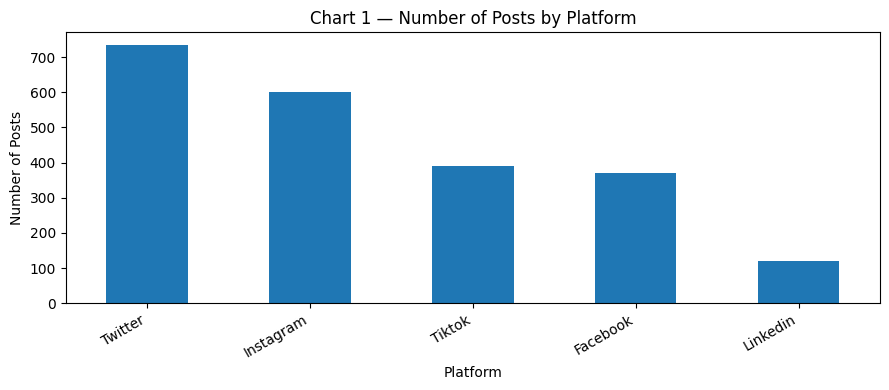

In [19]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9,4))
platform_counts.dropna().plot(kind='bar',ax=ax)
ax.set(title='Chart 1 — Number of Posts by Platform',xlabel='Platform',ylabel='Number of Posts')
plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.show()

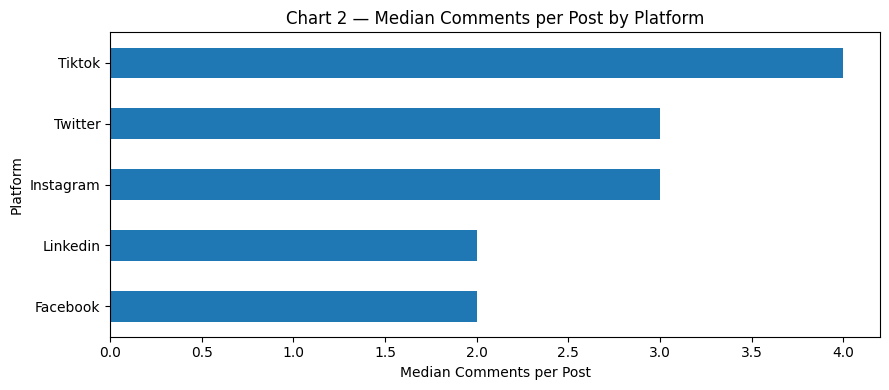

In [20]:
fig, ax = plt.subplots(figsize=(9,4))
platform_summary['median_comments'].dropna().sort_values().plot(kind='barh',ax=ax)
ax.set(title='Chart 2 — Median Comments per Post by Platform',xlabel='Median Comments per Post',ylabel='Platform')
plt.tight_layout();plt.show()

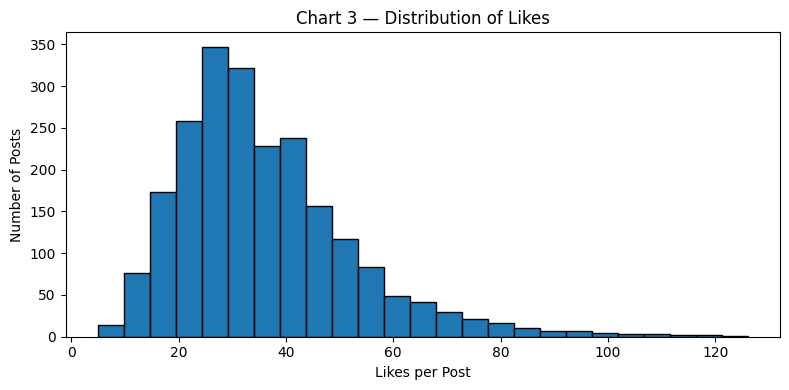

In [21]:
fig, ax = plt.subplots(figsize=(8,4))
df['likes'].dropna().plot(kind='hist',bins=25,ax=ax,edgecolor='black')
ax.set(title='Chart 3 — Distribution of Likes',xlabel='Likes per Post',ylabel='Number of Posts')
plt.tight_layout();plt.show()

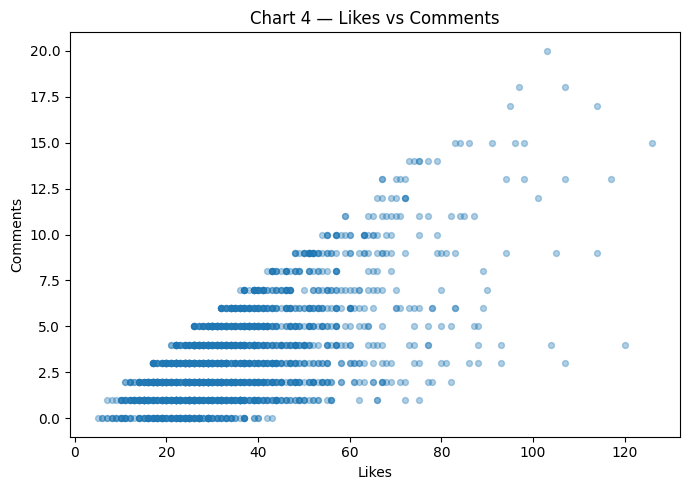

Pearson correlation (descriptive, not causal): 0.6574550690558502


In [22]:
fig, ax = plt.subplots(figsize=(7,5))
valid = df[['likes','comments']].dropna()
ax.scatter(valid['likes'],valid['comments'],alpha=0.35,s=18)
ax.set(title='Chart 4 — Likes vs Comments',xlabel='Likes',ylabel='Comments')
plt.tight_layout();plt.show()
print('Pearson correlation (descriptive, not causal):',valid['likes'].corr(valid['comments']))

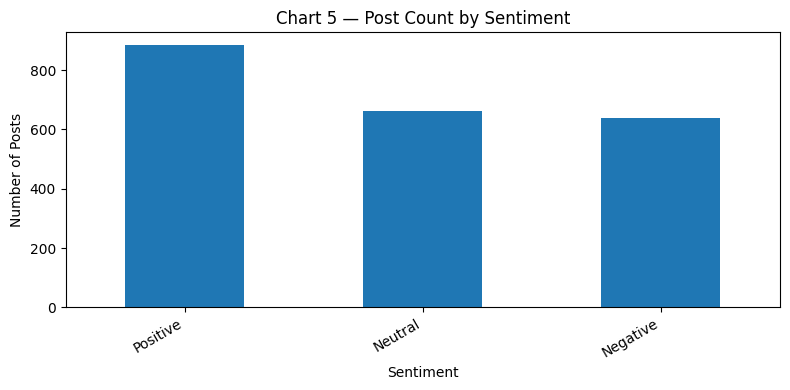

In [23]:
if 'sentiment' in df:
    fig,ax=plt.subplots(figsize=(8,4))
    df['sentiment'].value_counts().plot(kind='bar',ax=ax)
    ax.set(title='Chart 5 — Post Count by Sentiment',xlabel='Sentiment',ylabel='Number of Posts')
    plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.show()

## 7. Evidence-based findings (automatically calculated)
The following prints actual observations **only after loading the dataset**. These are descriptive comparisons, not proof that platform or sentiment caused engagement differences. A higher value from a small group may be unstable.

In [24]:
valid_platforms = platform_summary.dropna(subset=['median_comments'])
if len(valid_platforms)>=2:
    high=valid_platforms['median_comments'].idxmax()
    low=valid_platforms['median_comments'].idxmin()
    print(f'Finding 1: {high} has the highest observed median comments/post ({valid_platforms.loc[high,"median_comments"]:.1f}; n={int(valid_platforms.loc[high,"posts"])}).')
    print(f'Comparison: {low} has {valid_platforms.loc[low,"median_comments"]:.1f} median comments/post (n={int(valid_platforms.loc[low,"posts"])}).')
else: print('Finding 1: Insufficient platform groups with valid comments.')
if 'sentiment' in df:
    valid_sentiments=sentiment_summary.dropna(subset=['median_comments'])
    if len(valid_sentiments)>=2:
        high_s=valid_sentiments['median_comments'].idxmax()
        low_s=valid_sentiments['median_comments'].idxmin()
        print(f'Finding 2: {high_s} sentiment has the highest observed median comments/post ({valid_sentiments.loc[high_s,"median_comments"]:.1f}; n={int(valid_sentiments.loc[high_s,"posts"])}), compared with {low_s} ({valid_sentiments.loc[low_s,"median_comments"]:.1f}; n={int(valid_sentiments.loc[low_s,"posts"])}).')
    else: print('Finding 2: Insufficient sentiment groups with valid comments.')
print('Recommendation template: Test content resembling the stronger-performing category, using similar post counts and consistent metrics. Do not claim the category causes engagement.')

Finding 1: Tiktok has the highest observed median comments/post (4.0; n=391).
Comparison: Facebook has 2.0 median comments/post (n=371).
Finding 2: Positive sentiment has the highest observed median comments/post (3.0; n=883), compared with Neutral (2.0; n=662).
Recommendation template: Test content resembling the stronger-performing category, using similar post counts and consistent metrics. Do not claim the category causes engagement.


## 8. Scaling experiment — 1×, 10×, 100×, optional 1,000×
This is a **workload test**: repeated rows are copies, not new social-media evidence. We measure elapsed time for copying and grouping, and the DataFrame's memory footprint. Runtime varies by hardware and session; repeat runs if needed. The optional 2.26-million-row experiment is disabled by default to avoid exhausting Colab memory.

,multiplier,rows,dataframe_memory_MB,copy_and_group_seconds
0,1,2216,1.1558,0.0019
1,10,22160,11.5570,0.0080
2,100,221600,115.5684,0.0473


Original CSV size (MB): 0.33


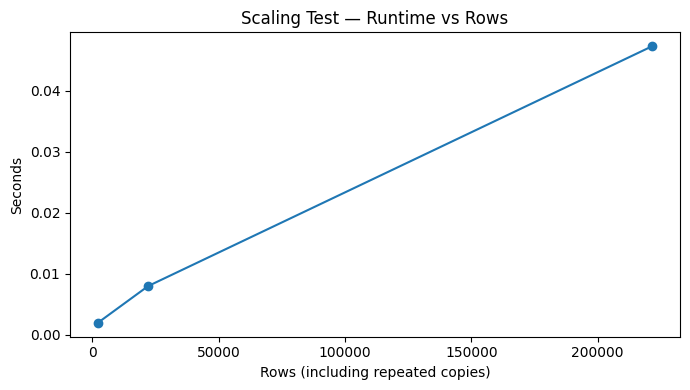

In [26]:
import time
from pathlib import Path

CSV_NAME = filename
results=[]
RUN_LARGE_TEST=False
multipliers=[1,10,100]+([1000] if RUN_LARGE_TEST else [])
for m in multipliers:
    start=time.perf_counter()
    enlarged=pd.concat([df]*m,ignore_index=True)
    grouped=enlarged.groupby('platform')['comments'].mean()
    seconds=time.perf_counter()-start
    results.append({'multiplier':m,'rows':len(enlarged),
                    'dataframe_memory_MB':enlarged.memory_usage(deep=True).sum()/1024**2,
                    'copy_and_group_seconds':seconds})
    del enlarged
scaling=pd.DataFrame(results)
display(scaling.round(4))
print('Original CSV size (MB):',round(Path(CSV_NAME).stat().st_size/1024**2,3))
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(scaling['rows'],scaling['copy_and_group_seconds'],marker='o')
ax.set(title='Scaling Test — Runtime vs Rows',xlabel='Rows (including repeated copies)',ylabel='Seconds')
plt.tight_layout();plt.show()

##Scaling Interpretation

**Measured change:** At 2,216 rows, the analysis took 0.0019 seconds; at 221,600 rows, it took 0.0473 seconds.

**Memory observation**: The largest tested DataFrame used approximately 115.57 MB.

**Bottleneck:** The operation that became more costly was creating larger DataFrames and calculating average comments using groupby().

**When Spark might help**: Spark may help when datasets become too large for a single machine's memory or processing time becomes too slow. Pandas successfully handled all tested dataset sizes.

**Important:** These experiments used repeated copies of the same dataset, not new social-media observations.

## 9. Analytics Concepts

**Classification:** Predict whether a social-media post will receive high or low engagement based on its characteristics.

**Clustering**:Group social-media posts with similar features, such as hashtags, text length, and follower count.

**Regression**: Predict numerical outcomes, such as the expected number of likes or comments on a post.

These techniques could support future marketing analysis. No machine-learning models were trained in this project.

##10. Final Student Report

##Business Question

How do social-media platforms and sentiment categories affect engagement, and what type of content should marketers test to improve performance?

##Dataset and Source

The dataset was obtained from Mrudula KP's GitHub repository, Social Media Sentiment Analysis.

The original dataset contained 2,260 records and 13 columns. Each row represents a social-media post.

Provenance/license: The dataset was obtained from a public GitHub repository recommended by the instructor. Its original data provenance and license have not been independently verified.

##Quality Checks

We found 44 exact duplicate rows, which were removed during data cleaning, leaving 2,216 records.

Missing values were checked, categorical labels were standardized, and numerical columns were converted to appropriate data types. Invalid negative engagement counts were treated as missing values rather than valid engagement.

The exact number of missing values should be taken from the notebook's data-quality output.

##Statistics and Charts

Statistic 1: TikTok had a median of 4 comments per post, while Facebook had a median of 2 comments per post.

Statistic 2: Positive-sentiment posts had a median of 3 comments, compared with 2 comments for neutral-sentiment posts.

Chart 1: The platform distribution chart shows the number of social-media records belonging to each platform.

Chart 2: The platform engagement chart compares engagement across different social-media platforms, helping identify differences in typical performance.

Two Findings with Evidence

Finding 1: TikTok posts received higher typical comment engagement than Facebook posts.

Evidence: TikTok had a median of 4 comments per post, compared with 2 for Facebook.

Finding 2: Positive-sentiment posts received higher typical comment engagement than neutral-sentiment posts.

Evidence: Positive posts had a median of 3 comments, while neutral posts had a median of 2 comments.

##Marketing Recommendation

Action to test: Marketers should test more engaging short-form video content and positive messaging, particularly on TikTok, while comparing performance with other platforms.

Measurement: Compare median comments per post, likes, and other available engagement metrics over a consistent testing period. Use sufficient sample sizes and consider differences in audience size and reach.

These findings show associations, not proof that platform choice or positive sentiment causes higher engagement.

##Scaling and Tools

The scaling experiment compared datasets containing 2,216, 22,160, and 221,600 rows.

Processing time increased from 0.0019 seconds to 0.0473 seconds, while memory usage increased from approximately 1.16 MB to 115.57 MB.

The experiment demonstrated that larger datasets require more processing time and memory.

Apache Spark may be useful for much larger datasets when distributed processing becomes necessary. However, Pandas successfully handled all tested workloads.

Limitations

The dataset is not verified as representative of Pakistani clothing brands.

Different social-media platforms may have different audience sizes and engagement patterns.

Without reliable reach and impressions data, we cannot calculate reach-based engagement rates.

Without advertising spend and conversion data, we cannot calculate ROAS.

Additionally, the scaling experiment used repeated records rather than new observations, so it cannot provide additional marketing evidence.

##Conclusion

The analysis found that TikTok posts had higher median comments than Facebook posts, while positive-sentiment posts had higher median comments than neutral posts.

The recommended next step is to test more short-form video content and positive messaging, then evaluate performance using consistent engagement metrics.

Future research could use larger, more representative datasets and explore machine-learning techniques to predict engagement.